# Kaplan Meier Curves

sources

- https://pmc.ncbi.nlm.nih.gov/articles/PMC3932959/
- https://allendowney.github.io/SurvivalAnalysisPython/02_kaplan_meier.html


## Survival


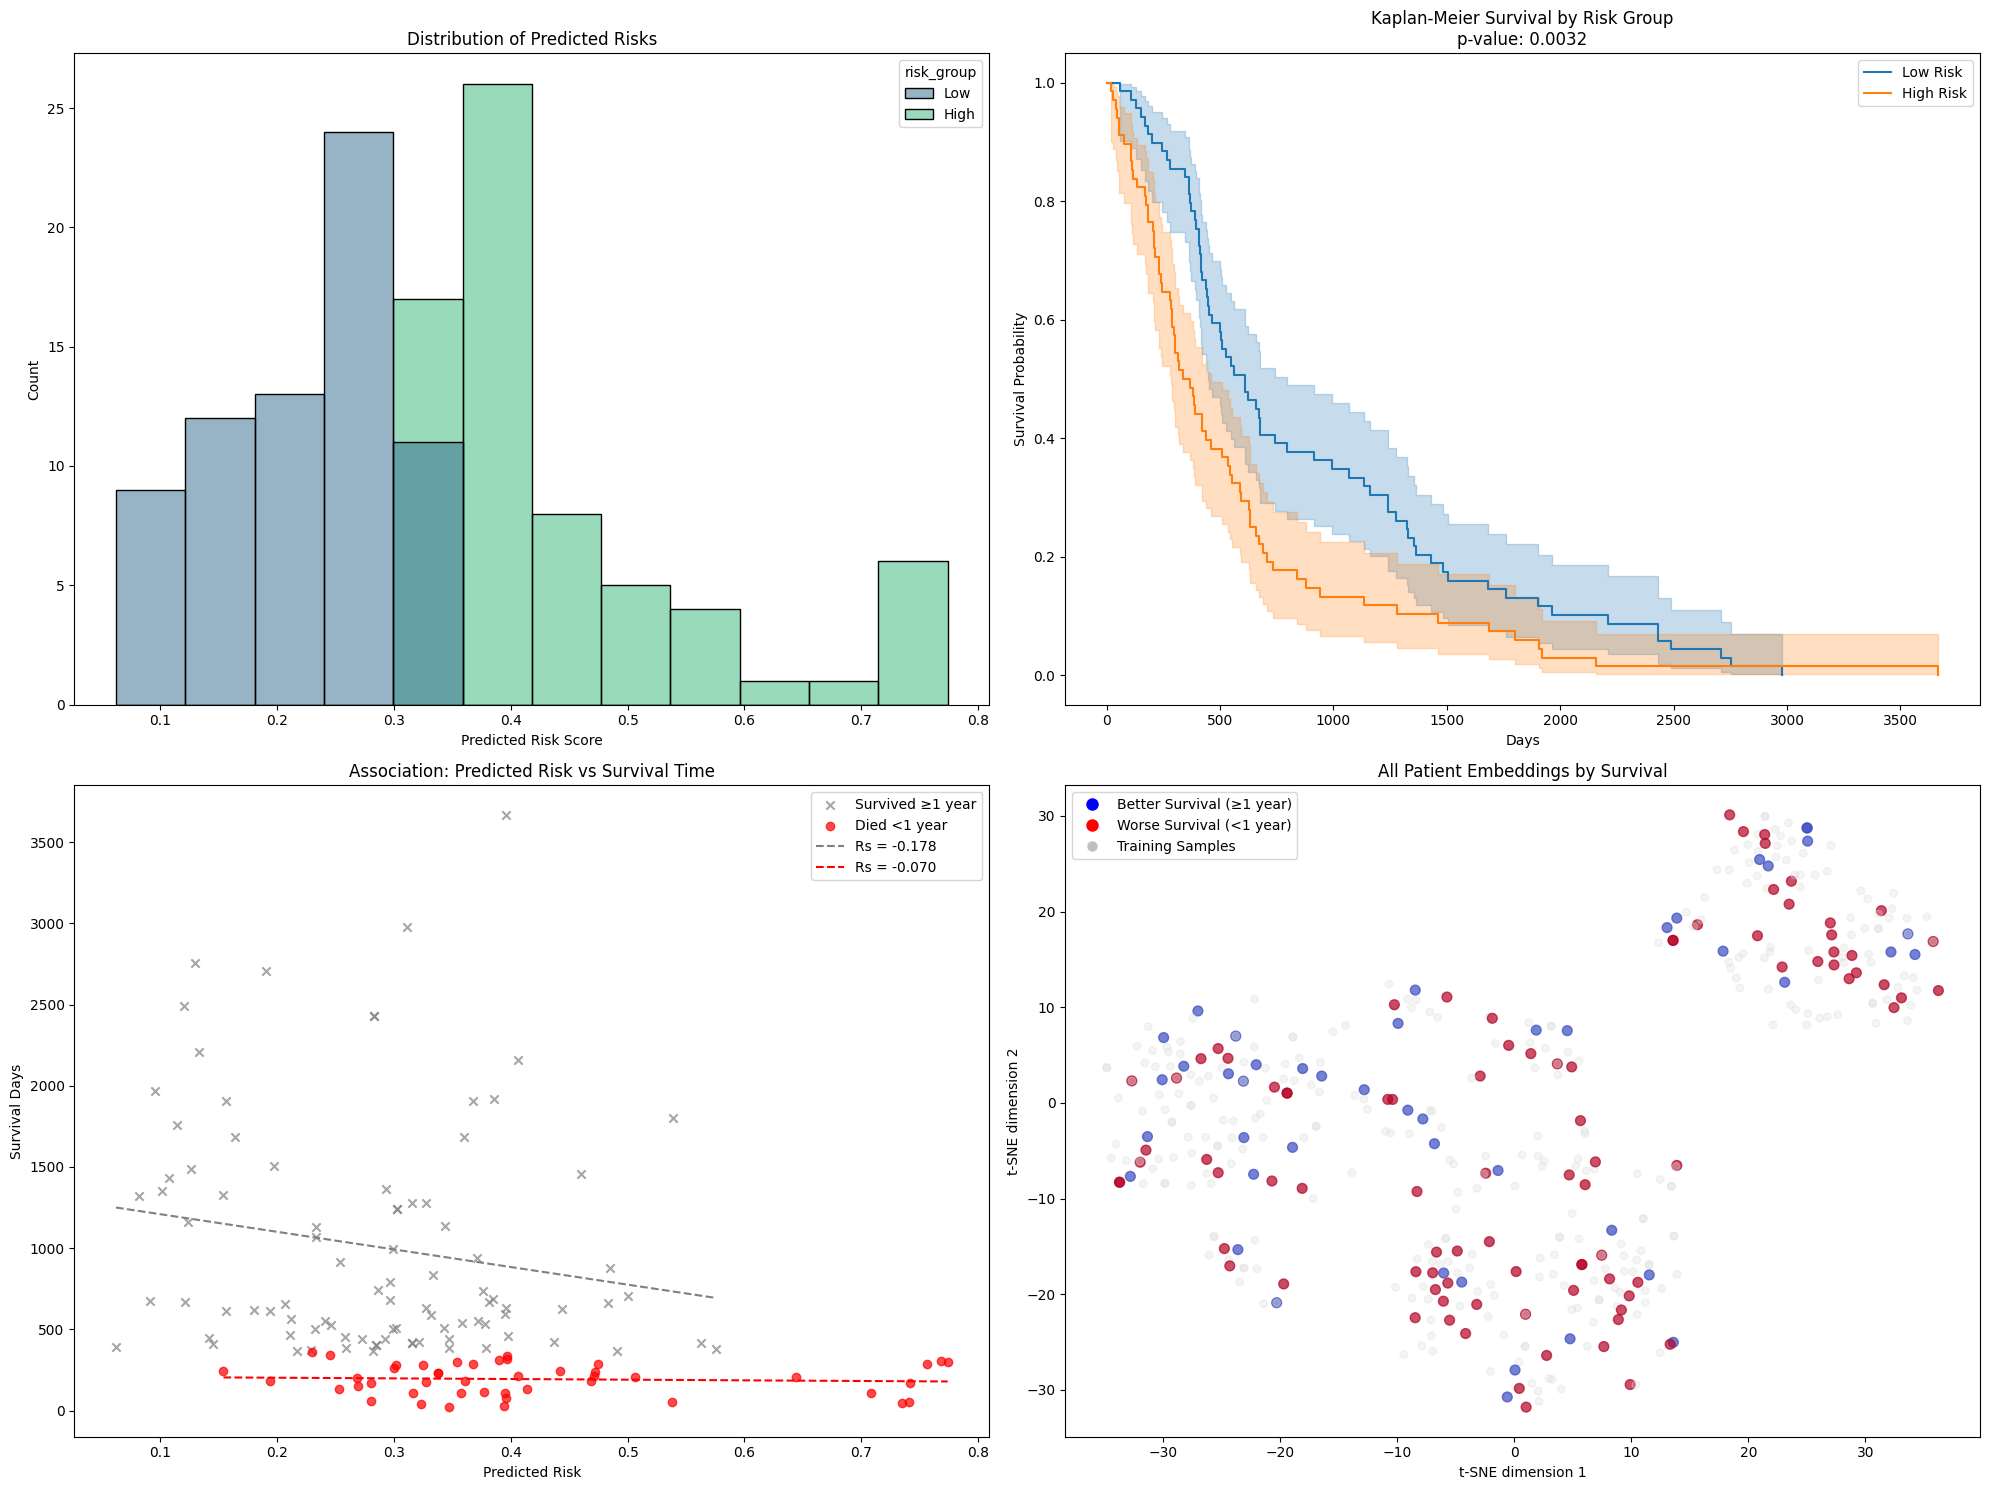

In [8]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.manifold import TSNE
import seaborn as sns
from scipy import stats

os_df = pd.read_csv("/home/neob/ai/paper/data/eval/os_eval.csv")
embeddings = np.load("/home/neob/ai/paper/embeddings/os/mnrl_full_data.npy")

# Filter valid data
valid_mask = os_df["survival_days"].notna() & os_df["one_year_survival"].notna()
filtered_embeddings = embeddings[valid_mask]
filtered_df = os_df[valid_mask].reset_index(drop=True)

# Split data for training the classifier
X_train, X_test, y_train, y_test = train_test_split(
    filtered_embeddings,
    filtered_df["one_year_survival"],
    test_size=0.3,
    random_state=42,
    stratify=filtered_df["one_year_survival"],
)

clf = RandomForestClassifier(
    n_estimators=1000, class_weight="balanced", random_state=7, n_jobs=-1
)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
y_pred_proba = clf.predict_proba(X_test)[:, 1]  # Probability of 1-year survival

test_indices = y_test.index
test_df = filtered_df.iloc[test_indices].copy()
test_df["predicted_survival"] = y_pred
test_df["predicted_risk"] = 1 - y_pred_proba  # Higher risk = lower survival probability

risk_threshold = np.median(test_df["predicted_risk"])
test_df["risk_group"] = pd.cut(
    test_df["predicted_risk"], bins=[0, risk_threshold, 1], labels=["Low", "High"]
)

fig, axs = plt.subplots(2, 2, figsize=(20, 15))

# Top left: Distribution of predicted risks
sns.histplot(
    data=test_df, x="predicted_risk", hue="risk_group", palette="viridis", ax=axs[0, 0]
)
axs[0, 0].set_title("Distribution of Predicted Risks")
axs[0, 0].set_xlabel("Predicted Risk Score")
axs[0, 0].set_ylabel("Count")

# Top right: Kaplan-Meier survival graph by risk group
kmf = KaplanMeierFitter()
for group in ["Low", "High"]:
    mask = test_df["risk_group"] == group
    if mask.sum() > 0:
        kmf.fit(
            test_df.loc[mask, "survival_days"],
            event_observed=np.ones(mask.sum()),
            label=f"{group} Risk",
        )
        kmf.plot_survival_function(ax=axs[0, 1])

# Log-rank test for risk groups
results = logrank_test(
    test_df.loc[test_df["risk_group"] == "Low", "survival_days"],
    test_df.loc[test_df["risk_group"] == "High", "survival_days"],
    event_observed_A=np.ones(sum(test_df["risk_group"] == "Low")),
    event_observed_B=np.ones(sum(test_df["risk_group"] == "High")),
)
p_value = results.p_value

axs[0, 1].set_title(f"Kaplan-Meier Survival by Risk Group\np-value: {p_value:.4f}")
axs[0, 1].set_xlabel("Days")
axs[0, 1].set_ylabel("Survival Probability")

# Bottom left: Association between predicted risks and survival times - MODIFIED
# Split by survival status (1-year survival yes/no)
survived = test_df["one_year_survival"] == 1
not_survived = test_df["one_year_survival"] == 0

# Scatter plot with different colors for survival status
axs[1, 0].scatter(
    test_df.loc[survived, "predicted_risk"],
    test_df.loc[survived, "survival_days"],
    c="gray",
    marker="x",
    alpha=0.7,
    label="Survived ≥1 year",
)
axs[1, 0].scatter(
    test_df.loc[not_survived, "predicted_risk"],
    test_df.loc[not_survived, "survival_days"],
    c="red",
    marker="o",
    alpha=0.7,
    label="Died <1 year",
)

# Calculate and plot regression lines for each group
# For survived group
if sum(survived) > 1:
    slope_surv, intercept_surv, r_surv, p_surv, std_err_surv = stats.linregress(
        test_df.loc[survived, "predicted_risk"], test_df.loc[survived, "survival_days"]
    )
    x_surv = np.array(
        [
            min(test_df.loc[survived, "predicted_risk"]),
            max(test_df.loc[survived, "predicted_risk"]),
        ]
    )
    y_surv = slope_surv * x_surv + intercept_surv
    axs[1, 0].plot(x_surv, y_surv, "gray", linestyle="--", label=f"Rs = {r_surv:.3f}")

# For not survived group
if sum(not_survived) > 1:
    slope_not, intercept_not, r_not, p_not, std_err_not = stats.linregress(
        test_df.loc[not_survived, "predicted_risk"],
        test_df.loc[not_survived, "survival_days"],
    )
    x_not = np.array(
        [
            min(test_df.loc[not_survived, "predicted_risk"]),
            max(test_df.loc[not_survived, "predicted_risk"]),
        ]
    )
    y_not = slope_not * x_not + intercept_not
    axs[1, 0].plot(x_not, y_not, "red", linestyle="--", label=f"Rs = {r_not:.3f}")

# Overall correlation
risk_corr, risk_p = stats.spearmanr(test_df["predicted_risk"], test_df["survival_days"])

axs[1, 0].set_title("Association: Predicted Risk vs Survival Time")
axs[1, 0].set_xlabel("Predicted Risk")
axs[1, 0].set_ylabel("Survival Days")
axs[1, 0].legend()

# Bottom right: t-SNE visualization of all patient embeddings
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
tsne_results = tsne.fit_transform(filtered_embeddings)

# Create a mask to identify test samples in the full dataset
test_mask = np.zeros(len(filtered_embeddings), dtype=bool)
test_mask[test_indices] = True

# Plot all embeddings
scatter = axs[1, 1].scatter(
    tsne_results[:, 0],
    tsne_results[:, 1],
    c=[
        filtered_df["one_year_survival"].values[i] if i in test_indices else 0.5
        for i in range(len(filtered_embeddings))
    ],
    cmap="coolwarm",
    alpha=[0.7 if i in test_indices else 0.3 for i in range(len(filtered_embeddings))],
    s=[50 if i in test_indices else 30 for i in range(len(filtered_embeddings))],
)
axs[1, 1].set_title("All Patient Embeddings by Survival")
axs[1, 1].set_xlabel("t-SNE dimension 1")
axs[1, 1].set_ylabel("t-SNE dimension 2")
legend_elements = [
    plt.Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor="blue",
        markersize=10,
        label="Better Survival (≥1 year)",
    ),
    plt.Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor="red",
        markersize=10,
        label="Worse Survival (<1 year)",
    ),
    plt.Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor="gray",
        markersize=8,
        alpha=0.5,
        label="Training Samples",
    ),
]
axs[1, 1].legend(handles=legend_elements)

plt.tight_layout()
plt.savefig("survival_analysis_combined.png", dpi=300, bbox_inches="tight")
plt.show()

## MGMT


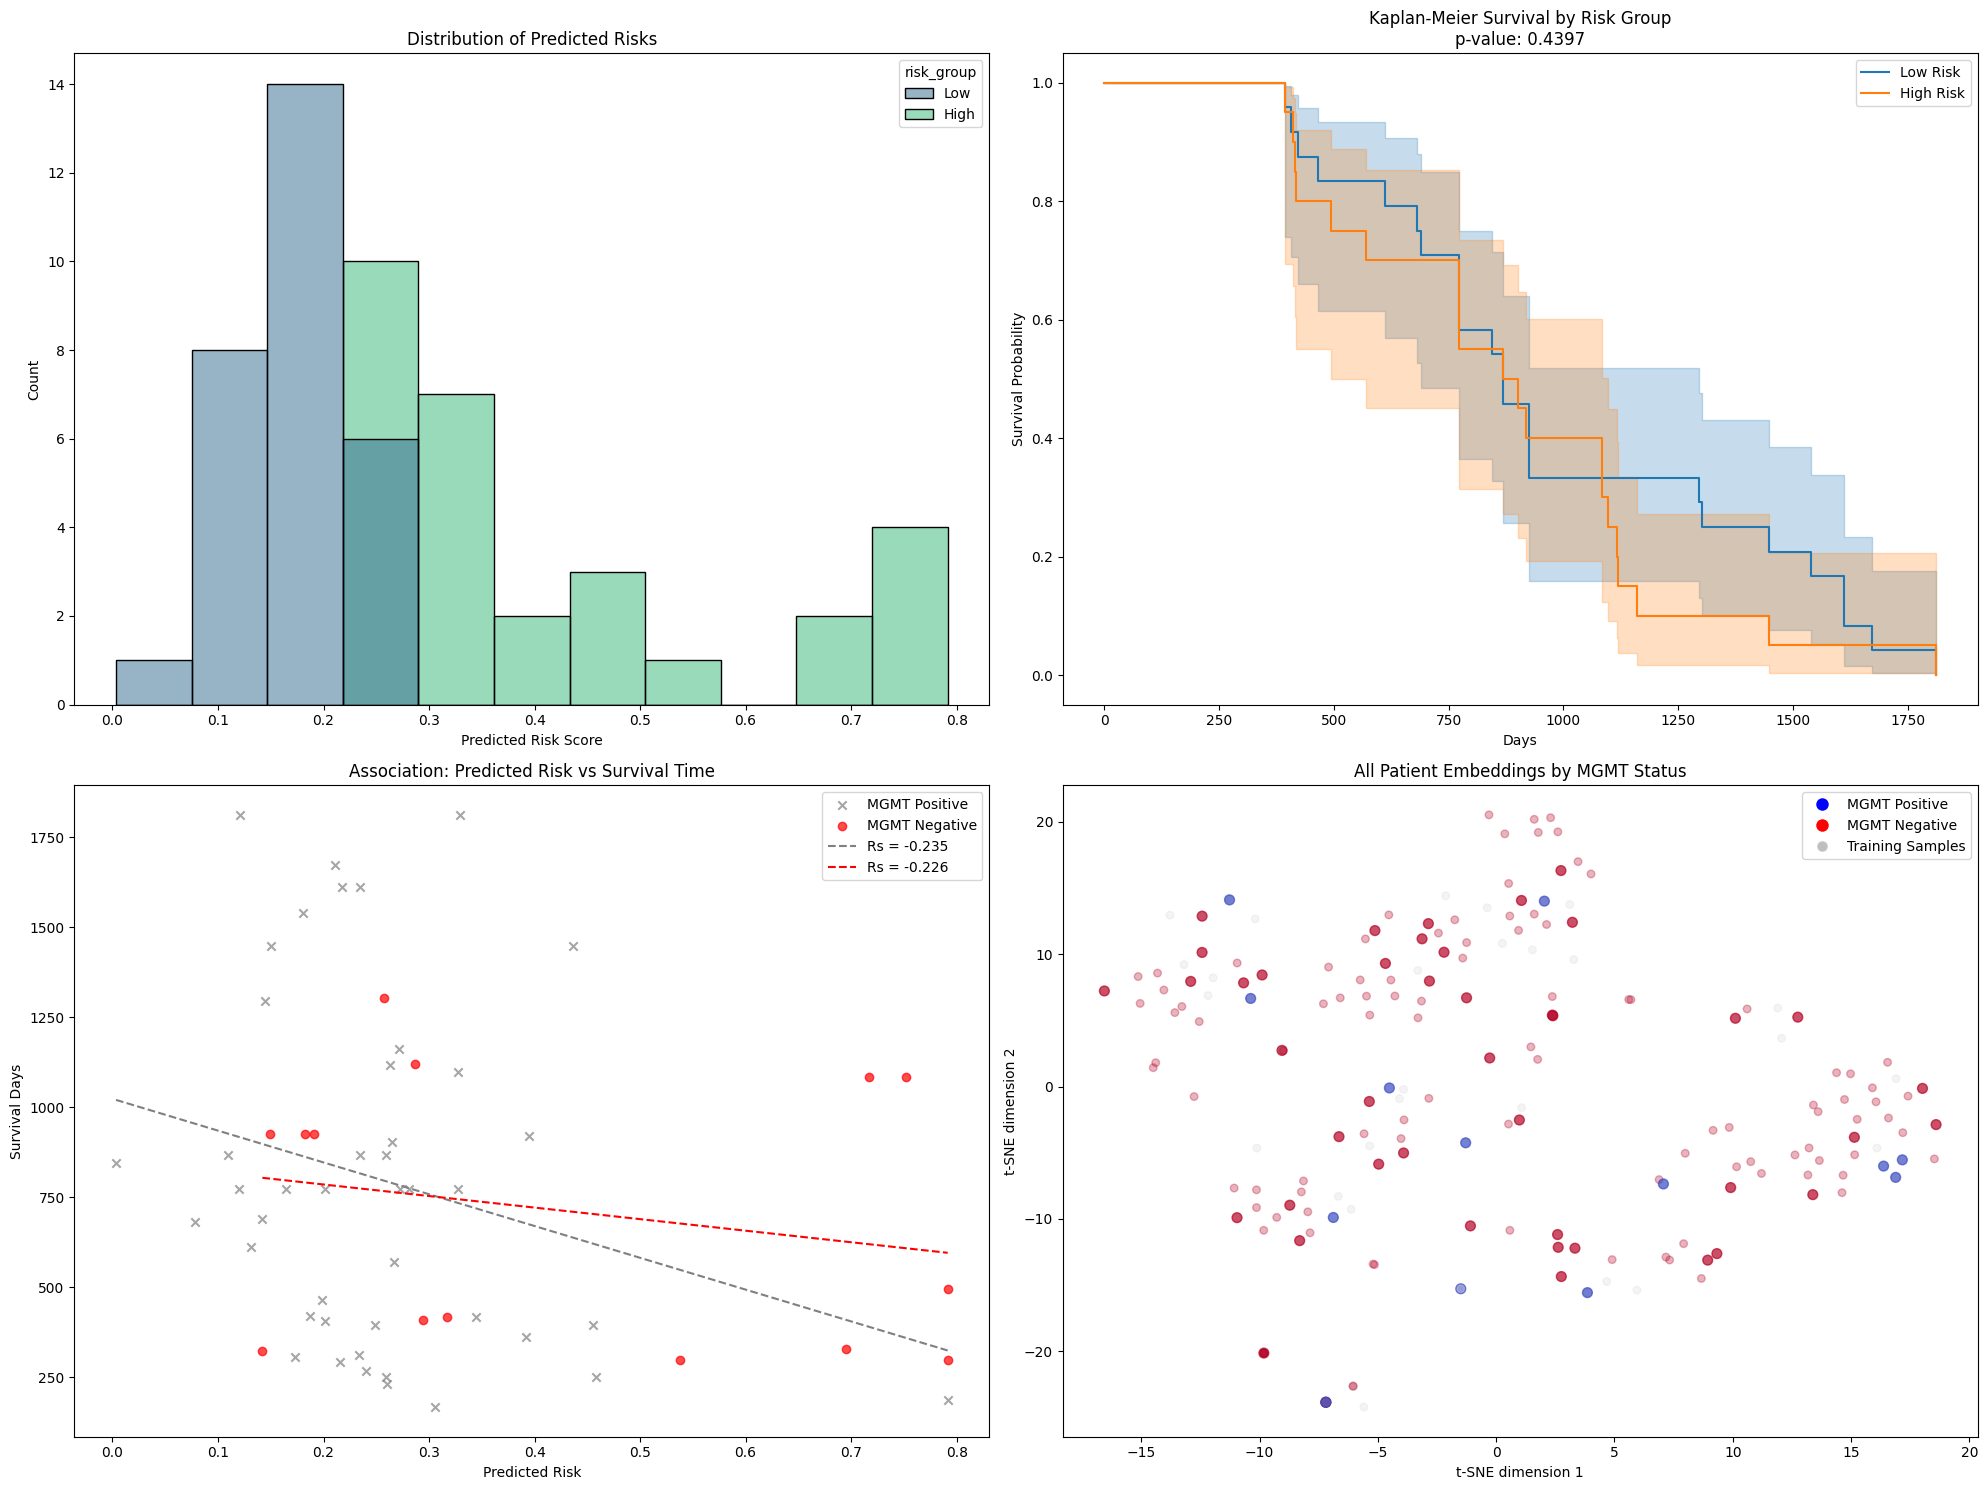

In [11]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.manifold import TSNE
import seaborn as sns
from scipy import stats

mgmt_df = pd.read_csv("/home/neob/ai/paper/data/eval/mgmt_eval.csv")
embeddings = np.load("/home/neob/ai/paper/embeddings/mgmt/mnrl_full_data.npy")

# Filter valid data
valid_mask = mgmt_df["mgmt"].notna()
filtered_embeddings = embeddings[valid_mask]
filtered_df = mgmt_df[valid_mask].reset_index(drop=True)

# Split data for training the classifier
X_train, X_test, y_train, y_test = train_test_split(
    filtered_embeddings,
    filtered_df["mgmt"].map({"positive": 1, "negative": 0}),
    test_size=0.3,
    random_state=42,
    stratify=filtered_df["mgmt"],
)

clf = RandomForestClassifier(
    n_estimators=1000, class_weight="balanced", random_state=7, n_jobs=-1
)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
y_pred_proba = clf.predict_proba(X_test)[:, 1]  # Probability of MGMT positive

test_indices = y_test.index
test_df = filtered_df.iloc[test_indices].copy()
test_df["predicted_mgmt"] = y_pred
test_df["predicted_risk"] = (
    1 - y_pred_proba
)  # Higher risk = lower MGMT positive probability

risk_threshold = np.median(test_df["predicted_risk"])
test_df["risk_group"] = pd.cut(
    test_df["predicted_risk"], bins=[0, risk_threshold, 1], labels=["Low", "High"]
)

fig, axs = plt.subplots(2, 2, figsize=(20, 15))

# Top left: Distribution of predicted risks
sns.histplot(
    data=test_df, x="predicted_risk", hue="risk_group", palette="viridis", ax=axs[0, 0]
)
axs[0, 0].set_title("Distribution of Predicted Risks")
axs[0, 0].set_xlabel("Predicted Risk Score")
axs[0, 0].set_ylabel("Count")

# Top right: Kaplan-Meier survival graph by risk group
kmf = KaplanMeierFitter()
for group in ["Low", "High"]:
    mask = test_df["risk_group"] == group
    if mask.sum() > 0:
        kmf.fit(
            test_df.loc[mask, "os_days"],
            event_observed=test_df.loc[mask, "survival"],
            label=f"{group} Risk",
        )
        kmf.plot_survival_function(ax=axs[0, 1])

# Log-rank test for risk groups
results = logrank_test(
    test_df.loc[test_df["risk_group"] == "Low", "os_days"],
    test_df.loc[test_df["risk_group"] == "High", "os_days"],
    event_observed_A=test_df.loc[test_df["risk_group"] == "Low", "survival"],
    event_observed_B=test_df.loc[test_df["risk_group"] == "High", "survival"],
)
p_value = results.p_value

axs[0, 1].set_title(f"Kaplan-Meier Survival by Risk Group\np-value: {p_value:.4f}")
axs[0, 1].set_xlabel("Days")
axs[0, 1].set_ylabel("Survival Probability")

# Bottom left: Association between predicted risks and survival times
# Split by MGMT status
mgmt_positive = test_df["mgmt"] == "positive"
mgmt_negative = test_df["mgmt"] == "negative"

# Scatter plot with different colors for MGMT status
axs[1, 0].scatter(
    test_df.loc[mgmt_positive, "predicted_risk"],
    test_df.loc[mgmt_positive, "os_days"],
    c="gray",
    marker="x",
    alpha=0.7,
    label="MGMT Positive",
)
axs[1, 0].scatter(
    test_df.loc[mgmt_negative, "predicted_risk"],
    test_df.loc[mgmt_negative, "os_days"],
    c="red",
    marker="o",
    alpha=0.7,
    label="MGMT Negative",
)

# Calculate and plot regression lines for each group
# For MGMT positive group
if sum(mgmt_positive) > 1:
    slope_pos, intercept_pos, r_pos, p_pos, std_err_pos = stats.linregress(
        test_df.loc[mgmt_positive, "predicted_risk"],
        test_df.loc[mgmt_positive, "os_days"],
    )
    x_pos = np.array(
        [
            min(test_df.loc[mgmt_positive, "predicted_risk"]),
            max(test_df.loc[mgmt_positive, "predicted_risk"]),
        ]
    )
    y_pos = slope_pos * x_pos + intercept_pos
    axs[1, 0].plot(x_pos, y_pos, "gray", linestyle="--", label=f"Rs = {r_pos:.3f}")

# For MGMT negative group
if sum(mgmt_negative) > 1:
    slope_neg, intercept_neg, r_neg, p_neg, std_err_neg = stats.linregress(
        test_df.loc[mgmt_negative, "predicted_risk"],
        test_df.loc[mgmt_negative, "os_days"],
    )
    x_neg = np.array(
        [
            min(test_df.loc[mgmt_negative, "predicted_risk"]),
            max(test_df.loc[mgmt_negative, "predicted_risk"]),
        ]
    )
    y_neg = slope_neg * x_neg + intercept_neg
    axs[1, 0].plot(x_neg, y_neg, "red", linestyle="--", label=f"Rs = {r_neg:.3f}")

# Overall correlation
risk_corr, risk_p = stats.spearmanr(test_df["predicted_risk"], test_df["os_days"])

axs[1, 0].set_title("Association: Predicted Risk vs Survival Time")
axs[1, 0].set_xlabel("Predicted Risk")
axs[1, 0].set_ylabel("Survival Days")
axs[1, 0].legend()

# Bottom right: t-SNE visualization of all patient embeddings
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
tsne_results = tsne.fit_transform(filtered_embeddings)

# Create a mask to identify test samples in the full dataset
test_mask = np.zeros(len(filtered_embeddings), dtype=bool)
test_mask[test_indices] = True

# Plot all embeddings
scatter = axs[1, 1].scatter(
    tsne_results[:, 0],
    tsne_results[:, 1],
    c=[
        1
        if filtered_df["mgmt"].iloc[i] == "positive"
        else 0
        if i in test_indices
        else 0.5
        for i in range(len(filtered_embeddings))
    ],
    cmap="coolwarm",
    alpha=[0.7 if i in test_indices else 0.3 for i in range(len(filtered_embeddings))],
    s=[50 if i in test_indices else 30 for i in range(len(filtered_embeddings))],
)
axs[1, 1].set_title("All Patient Embeddings by MGMT Status")
axs[1, 1].set_xlabel("t-SNE dimension 1")
axs[1, 1].set_ylabel("t-SNE dimension 2")
legend_elements = [
    plt.Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor="blue",
        markersize=10,
        label="MGMT Positive",
    ),
    plt.Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor="red",
        markersize=10,
        label="MGMT Negative",
    ),
    plt.Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor="gray",
        markersize=8,
        alpha=0.5,
        label="Training Samples",
    ),
]
axs[1, 1].legend(handles=legend_elements)

plt.tight_layout()
plt.savefig("mgmt_analysis_combined.png", dpi=300, bbox_inches="tight")
plt.show()